# Final 11-Feature ML Model with Rs from EIS, Seed 42

This notebook is a standalone reproducible workflow for the corrected 561-sample no-BO dataset using the 11-feature descriptor set selected from seed-42 backward elimination.

It follows the same data-processing logic as the fixed-12 final-model workflow:

- rebuild electrochemical inputs from `data_extraction/all_data`
- estimate `Rs (Ohm)` from high-frequency EIS real impedance
- calculate `E_actual` from Et traces over 1100-1200 s
- extract `I_raw` from LSV at -1.0 V
- apply potential-dependent shifts to `work_function`, `pzc`, and `E_std` descriptors
- train Random Forest, Extra Trees, and XGBoost using random seed 42
- save prediction, SHAP, and feature-importance plots

Primary outputs are written to `outputs/final_model_11features_561_seed42_rs_from_eis`.

LSV geometry note: `Ag-Ce`, `Co-V`, and `Mo-Mg` were measured with a 2 cm2 geometry. The notebook reads `data_extraction/all_data/LSV/lsv_geometry_area_metadata.csv` and area-normalizes `I_raw` to the standard 1 cm2 convention during feature construction. For eta10 extraction from those raw LSV curves, the comparable value is raw eta20.



In [1]:
from pathlib import Path
import os


def find_repo_root(start=None):
    path = Path.cwd() if start is None else Path(start)
    for candidate in [path, *path.parents]:
        if (candidate / "hd_separation_ml").exists() and (candidate / "0-Figures").exists():
            return candidate
    raise FileNotFoundError("Could not locate HD_separation repo root.")


PROJECT_ROOT = find_repo_root() / "hd_separation_ml"
os.chdir(PROJECT_ROOT)
print(f"Working directory: {PROJECT_ROOT}")


Working directory: C:\Users\yibinjiang\Documents\GitHub\HD_separation\hd_separation_ml


In [2]:
import json
import os
import re
import shutil
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import xgboost as xgb
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split

warnings.filterwarnings("ignore")

plt.rcParams["font.sans-serif"] = ["Arial"]
plt.rcParams["axes.unicode_minus"] = False

RANDOM_SEED = 42
ET_WINDOW = (1100, 1200)
LSV_TARGET_V = -1.0
RS_TOP_N = 3
IR_CURRENT_A = 0.05
IR_FACTOR = 0.9
SHE_OFFSET_V = 0.098
PH14_OFFSET_V = 0.0592 * 14
ALL_DATA = Path("data_extraction") / "all_data"

LSV_GEOMETRY_METADATA = ALL_DATA / "LSV" / "lsv_geometry_area_metadata.csv"
STANDARD_LSV_GEOMETRY_AREA_CM2 = 1.0
OUTPUT_DIR = Path("outputs") / "final_model_11features_561_seed42_rs_from_eis"

METAL_DESCRIPTOR_BASE_COLS = [
    "work_function",
    "pzc",
    "MM_bond",
    "E_std",
    "FE_ads_avg",
    "delta_EOH",
    "electronegativity",
    "MH_bond_kJ",
    "MD_bond_kJ",
    "Frequency_OH",
    "Frequency_H",
    "Frequency_D",
    "delta_ZPE_H",
]

SELECTED_FEATURES = [
    "I_raw",
    "work_function_element2",
    "MM_bond_element2",
    "E_std_element1",
    "FE_ads_avg_element1",
    "delta_EOH_element1",
    "delta_EOH_element2",
    "electronegativity_element1",
    "electronegativity_element2",
    "MH_bond_kJ_element2",
    "MD_bond_kJ_element1",
]


def extract_elements_from_sample(sample_name):
    base_name = re.sub(r"\d+$", "", str(sample_name))
    parts = base_name.split("-")
    if len(parts) == 2:
        return parts[0], parts[1]
    return None, None


def split_numeric_line(line):
    return [x for x in re.split(r"[,\s\t]+", line.strip()) if x]


def read_three_column_curve(path):
    rows = []
    for line in Path(path).read_text(errors="replace").splitlines():
        parts = split_numeric_line(line)
        if len(parts) < 3:
            continue
        try:
            rows.append([float(parts[0]), float(parts[1]), float(parts[2])])
        except ValueError:
            continue
    if not rows:
        raise ValueError(f"No Potential/Current/Time rows parsed from {path}")
    return pd.DataFrame(rows, columns=["Potential(V)", "Current(A)", "Time(s)"])


def read_eis_table(path):
    rows = []
    for line in Path(path).read_text(errors="replace").splitlines():
        parts = split_numeric_line(line)
        if len(parts) >= 9:
            try:
                rows.append([float(parts[0]), float(parts[4]), float(parts[5]), float(parts[6]), float(parts[7])])
                continue
            except ValueError:
                pass
        if len(parts) >= 5:
            try:
                rows.append([float(parts[0]), float(parts[1]), float(parts[2]), float(parts[3]), float(parts[4])])
            except ValueError:
                pass
    if not rows:
        raise ValueError(f"No EIS rows parsed from {path}")
    return pd.DataFrame(rows, columns=["Frequency(Hz)", "Zreal(Ohm)", "Zimag(Ohm)", "Zabs(Ohm)", "Phase(deg)"])


def estimate_rs_from_eis(path, top_n=RS_TOP_N):
    eis = read_eis_table(path).replace([np.inf, -np.inf], np.nan).dropna(subset=["Frequency(Hz)", "Zreal(Ohm)"])
    eis = eis[eis["Frequency(Hz)"] > 0].sort_values("Frequency(Hz)", ascending=False)
    zreal = eis["Zreal(Ohm)"].to_numpy(dtype=float)
    zreal = zreal[np.isfinite(zreal)]
    if len(zreal) == 0:
        return np.nan
    return float(np.median(zreal[:top_n]))


def mean_et_potential(path, window=ET_WINDOW):
    et = read_three_column_curve(path)
    lo, hi = window
    sub = et[(et["Time(s)"] >= lo) & (et["Time(s)"] <= hi)]
    if len(sub) == 0:
        return np.nan
    return float(sub["Potential(V)"].mean())



def load_lsv_geometry_area_map():
    """Return per-sample LSV geometry areas. Samples not listed use 1 cm2."""
    if not LSV_GEOMETRY_METADATA.exists():
        return {}
    meta = pd.read_csv(LSV_GEOMETRY_METADATA)
    required = {"catalyst", "geometry_area_cm2"}
    if not required.issubset(meta.columns):
        raise ValueError(f"{LSV_GEOMETRY_METADATA} must contain columns: {sorted(required)}")
    meta = meta.copy()
    meta["catalyst"] = meta["catalyst"].astype(str)
    meta["geometry_area_cm2"] = pd.to_numeric(meta["geometry_area_cm2"], errors="coerce")
    meta = meta.dropna(subset=["catalyst", "geometry_area_cm2"])
    return dict(zip(meta["catalyst"], meta["geometry_area_cm2"]))


def correct_lsv_current_for_geometry(sample, current_mA, geometry_area_map):
    """Convert LSV current to the standard 1 cm2 geometry convention."""
    area_cm2 = float(geometry_area_map.get(sample, STANDARD_LSV_GEOMETRY_AREA_CM2))
    if not np.isfinite(area_cm2) or area_cm2 <= 0:
        raise ValueError(f"Invalid LSV geometry area for {sample}: {area_cm2}")
    return float(current_mA) / area_cm2, area_cm2

def current_from_lsv(path, target_potential=LSV_TARGET_V):
    lsv_df = read_three_column_curve(path)
    potential = lsv_df["Potential(V)"].values
    current = lsv_df["Current(A)"].values

    original_potentials = np.arange(-0.92, -1.51, -0.02)
    potential_reversed = potential[::-1]
    current_reversed = current[::-1]
    if np.any(np.diff(potential_reversed) < 0):
        order = np.argsort(potential)
        potential_reversed = potential[order]
        current_reversed = current[order]

    f_current = np.interp(original_potentials, potential_reversed, current_reversed)
    f_current_mA = f_current * 1000
    idx = np.argmin(np.abs(original_potentials - target_potential))
    return float(f_current_mA[idx])


def load_metal_descriptor_table():
    eh_file = Path("EH_extra.xlsx")
    print(f"Reading metal descriptors from: {eh_file}")
    sheet1 = pd.read_excel(eh_file, sheet_name="Sheet1")
    sheet2 = pd.read_excel(eh_file, sheet_name="Sheet2")

    sheet1 = sheet1.rename(columns={
        "Unnamed: 0": "element",
        "Work function (eV)": "work_function",
        "pzc": "pzc",
        "M-M": "MM_bond",
        "E(M-H) (kJ/mol)": "MH_bond_kJ",
        "E(M-D) (kJ/mol)": "MD_bond_kJ",
        "delta_ZPE_H (eV)": "delta_ZPE_H",
    })

    for col in [
        "electronegativity", "work_function", "pzc", "MM_bond", "MH_bond_kJ",
        "delta_EOH", "Frequency_H", "Frequency_OH", "Frequency_D",
        "delta_ZPE_H", "MD_bond_kJ",
    ]:
        sheet1[col] = pd.to_numeric(sheet1[col], errors="coerce")

    sheet2 = sheet2.rename(columns={"Unnamed: 0": "element"})
    sheet2["element"] = sheet2["element"].ffill()
    ads_avg = (
        sheet2.groupby("element")["Free Energy of Adsorption (eV)"]
        .mean()
        .reset_index()
        .rename(columns={"Free Energy of Adsorption (eV)": "FE_ads_avg"})
    )

    metal_df = pd.merge(sheet1, ads_avg, on="element", how="left")
    e_std = {
        "Ag": 0.80, "Al": -1.66, "Au": 1.52, "Ba": -2.91, "Ca": -2.87,
        "Cd": -0.40, "Ce": -2.34, "Co": -0.28, "Cr": -0.74, "Cu": 0.34,
        "Eu": -2.81, "Fe": -0.44, "Ga": -0.53, "In": -0.34, "La": -2.38,
        "Mg": -2.37, "Mn": -1.19, "Mo": -0.20, "Nb": -1.10, "Ni": -0.25,
        "Pb": -0.13, "Pd": 0.92, "Pt": 1.20, "Ru": 0.455, "Sc": -2.08,
        "Sr": -2.90, "V": -1.18, "W": -0.12, "Y": -2.37, "Zn": -0.76,
    }
    metal_df["E_std"] = metal_df["element"].map(e_std)

    for col in METAL_DESCRIPTOR_BASE_COLS:
        metal_df[col] = pd.to_numeric(metal_df[col], errors="coerce")

    return metal_df


def build_feature_matrix():
    print("\n" + "=" * 100)
    print("STEP 1: BUILD FEATURE MATRIX")
    print("=" * 100)

    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    metal_df = load_metal_descriptor_table()
    lsv_geometry_area_map = load_lsv_geometry_area_map()
    metal_desc_dicts = {
        col: metal_df.set_index("element")[col].to_dict()
        for col in METAL_DESCRIPTOR_BASE_COLS
    }

    sep = pd.read_excel(Path("data_extraction") / "separation_coefficient.xlsx")
    sep["sample"] = sep["sample"].astype(str).str.replace(r"\.json$", "", regex=True)
    sep["separation_coefficient"] = pd.to_numeric(sep["separation_coefficient"], errors="coerce")
    sep = sep.dropna(subset=["sample", "separation_coefficient"]).drop_duplicates("sample", keep="first")
    print(f"Total samples in separation_coefficient.xlsx: {len(sep)}")

    records = []
    skipped = []
    for _, row in sep.iterrows():
        sample = row["sample"]
        if sample[-1].isdigit():
            skipped.append({"sample": sample, "reason": "Bayesian sample"})
            continue

        lsv_path = ALL_DATA / "LSV" / f"{sample}.txt"
        et_path = ALL_DATA / "Et" / f"{sample}.txt"
        eis_path = ALL_DATA / "EIS" / f"{sample}.txt"
        missing = [name for name, path in [("LSV", lsv_path), ("Et", et_path), ("EIS", eis_path)] if not path.exists()]
        if missing:
            skipped.append({"sample": sample, "reason": "missing_" + "+".join(missing)})
            continue

        try:
            e_actual = mean_et_potential(et_path)
            rs = estimate_rs_from_eis(eis_path, top_n=RS_TOP_N)
            current_at_target = current_from_lsv(lsv_path, target_potential=LSV_TARGET_V)
            current_at_target, lsv_geometry_area_cm2 = correct_lsv_current_for_geometry(
                sample, current_at_target, lsv_geometry_area_map
            )
        except Exception as exc:
            skipped.append({"sample": sample, "reason": f"parse_error: {exc}"})
            continue

        records.append({
            "sample": sample,
            "E_actual": e_actual,
            "Rs_from_EIS": rs,
            "E_IR_corrected_final": e_actual + rs * IR_CURRENT_A * IR_FACTOR,
            "Potential_vs_RHE_like": e_actual + PH14_OFFSET_V + SHE_OFFSET_V + rs * IR_CURRENT_A,
            "LSV_geometry_area_cm2": lsv_geometry_area_cm2,
            "I_raw": current_at_target,
            "separation_coefficient": float(row["separation_coefficient"]),
        })

    merged = pd.DataFrame(records).sort_values("sample").reset_index(drop=True)
    skipped_df = pd.DataFrame(skipped)
    print(f"No-BO samples retained: {len(merged)}")
    if len(skipped_df):
        print("Skipped sample reasons:")
        print(skipped_df["reason"].value_counts().to_string())

    merged[["element1", "element2"]] = merged["sample"].apply(lambda s: pd.Series(extract_elements_from_sample(s)))

    expanded_metal_cols = []
    for desc_col in METAL_DESCRIPTOR_BASE_COLS:
        col1 = f"{desc_col}_element1"
        col2 = f"{desc_col}_element2"
        merged[col1] = merged["element1"].map(metal_desc_dicts[desc_col])
        merged[col2] = merged["element2"].map(metal_desc_dicts[desc_col])
        median_val = pd.concat([merged[col1], merged[col2]], axis=0).median()
        merged[col1] = merged[col1].fillna(median_val)
        merged[col2] = merged[col2].fillna(median_val)
        expanded_metal_cols.extend([col1, col2])

    # Apply the same potential-dependent descriptor shifts as the fixed-12 notebook.
    offset = merged["E_IR_corrected_final"] + SHE_OFFSET_V
    for col in [c for c in expanded_metal_cols if ("pzc" in c or "E_std" in c)]:
        merged[col] = merged[col] - offset
    for col in [c for c in expanded_metal_cols if "work_function" in c]:
        merged[col] = merged[col] + offset

    X = merged[SELECTED_FEATURES].copy()
    y = merged["separation_coefficient"].copy()
    valid_mask = ~(X.isnull().any(axis=1) | y.isnull())
    X = X[valid_mask].reset_index(drop=True)
    y = y[valid_mask].reset_index(drop=True)
    metadata = merged.loc[valid_mask, [
        "sample", "element1", "element2", "E_actual", "Rs_from_EIS",
        "E_IR_corrected_final", "Potential_vs_RHE_like", "LSV_geometry_area_cm2", "I_raw", "separation_coefficient",
    ]].reset_index(drop=True)

    pd.concat([metadata, X], axis=1).to_csv(OUTPUT_DIR / "feature_matrix_11features.csv", index=False)
    skipped_df.to_csv(OUTPUT_DIR / "skipped_samples.csv", index=False)
    pd.DataFrame({"feature": SELECTED_FEATURES}).to_csv(OUTPUT_DIR / "selected_features.csv", index=False)

    print(f"Feature matrix shape: {X.shape}")
    print("Selected features:")
    for i, feat in enumerate(SELECTED_FEATURES, 1):
        print(f"  {i}. {feat}")

    return X, y, metadata


In [3]:
if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

X, y, metadata = build_feature_matrix()
print("\nData preview:")
display(pd.concat([metadata[["sample", "separation_coefficient"]], X], axis=1).head())


STEP 1: BUILD FEATURE MATRIX
Reading metal descriptors from: EH_extra.xlsx


Total samples in separation_coefficient.xlsx: 709


No-BO samples retained: 561
Skipped sample reasons:
reason
Bayesian sample    148
Feature matrix shape: (561, 11)
Selected features:
  1. I_raw
  2. work_function_element2
  3. MM_bond_element2
  4. E_std_element1
  5. FE_ads_avg_element1
  6. delta_EOH_element1
  7. delta_EOH_element2
  8. electronegativity_element1
  9. electronegativity_element2
  10. MH_bond_kJ_element2
  11. MD_bond_kJ_element1

Data preview:


,sample,separation_coefficient,I_raw,work_function_element2,MM_bond_element2,E_std_element1,FE_ads_avg_element1,delta_EOH_element1,delta_EOH_element2,electronegativity_element1,electronegativity_element2,MH_bond_kJ_element2,MD_bond_kJ_element1
0,Ag-Ag,7.2,-0.981283,2.760420,11.5,2.339580,0.373333,0.56,0.56,1.93,1.93,245.312414,242.536329
1,Ag-Al,7.0,-1.010542,2.611165,12.6,2.378835,0.373333,0.56,-0.77,1.93,1.61,274.165746,242.536329
2,Ag-Au,3.1,-0.926685,3.284136,15.2,2.295864,0.373333,0.56,1.37,1.93,2.54,257.172639,242.536329
3,Ag-Ba,7.8,-1.446079,1.199648,6.0,2.300352,0.373333,0.56,-0.77,1.93,0.89,392.347345,242.536329
4,Ag-Ca,7.9,-0.949016,1.374239,7.5,2.295761,0.373333,0.56,-2.26,1.93,1.00,368.846378,242.536329


In [4]:
y_bins = pd.qcut(y, q=10, labels=False, duplicates="drop")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_SEED,
    stratify=y_bins,
)

print(f"Data split: {X_train.shape[0]} train, {X_test.shape[0]} test")


Data split: 448 train, 113 test


In [5]:
def train_models_with_selected_features(X_train, X_test, y_train, y_test):
    print("\n" + "=" * 100)
    print("STEP 2: TRAIN MODELS WITH SELECTED FEATURES")
    print("=" * 100)

    models_config = {
        "Random Forest": {
            "model": RandomForestRegressor(random_state=RANDOM_SEED),
            "params": {
                "n_estimators": [100, 200],
                "max_depth": [10, 15, None],
                "min_samples_split": [2, 5],
                "min_samples_leaf": [1, 2],
            },
        },
        "Extra Trees": {
            "model": ExtraTreesRegressor(random_state=RANDOM_SEED),
            "params": {
                "n_estimators": [100, 200],
                "max_depth": [10, 15, None],
                "min_samples_split": [2, 5],
                "min_samples_leaf": [1, 2],
            },
        },
        "XGBoost": {
            "model": xgb.XGBRegressor(random_state=RANDOM_SEED),
            "params": {
                "n_estimators": [50, 100, 200],
                "max_depth": [3, 5, 7],
                "learning_rate": [0.05, 0.1],
                "subsample": [0.8, 1.0],
            },
        },
    }

    rows = []
    best_model_info = None
    best_score = -np.inf

    for model_name, config in models_config.items():
        print(f"\n--- {model_name} ---")
        grid_search = GridSearchCV(config["model"], config["params"], cv=5, scoring="r2", n_jobs=-1, verbose=0)
        grid_search.fit(X_train[SELECTED_FEATURES], y_train)
        model = grid_search.best_estimator_
        y_train_pred = model.predict(X_train[SELECTED_FEATURES])
        y_test_pred = model.predict(X_test[SELECTED_FEATURES])
        train_r2 = r2_score(y_train, y_train_pred)
        test_r2 = r2_score(y_test, y_test_pred)
        train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
        test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
        overfitting = train_r2 - test_r2
        print(f"Best params: {grid_search.best_params_}")
        print(f"Best CV score: {grid_search.best_score_:.4f}")
        print(f"Train R2: {train_r2:.4f}, RMSE: {train_rmse:.4f}")
        print(f"Test R2: {test_r2:.4f}, RMSE: {test_rmse:.4f}")
        print(f"Overfitting: {overfitting:.4f}")

        info = {
            "model_name": model_name,
            "best_params": json.dumps(grid_search.best_params_),
            "best_cv_score": grid_search.best_score_,
            "train_r2": train_r2,
            "test_r2": test_r2,
            "train_rmse": train_rmse,
            "test_rmse": test_rmse,
            "overfitting": overfitting,
            "model": model,
            "X_train": X_train[SELECTED_FEATURES].copy(),
            "X_test": X_test[SELECTED_FEATURES].copy(),
            "y_train": y_train.copy(),
            "y_test": y_test.copy(),
            "y_train_pred": y_train_pred,
            "y_test_pred": y_test_pred,
        }
        rows.append(info)
        if test_r2 > best_score:
            best_score = test_r2
            best_model_info = info

    results_df = pd.DataFrame([
        {k: v for k, v in item.items() if k not in ["model", "X_train", "X_test", "y_train", "y_test", "y_train_pred", "y_test_pred"]}
        for item in rows
    ]).sort_values("test_r2", ascending=False)
    results_df.to_csv(OUTPUT_DIR / "final_ml_I_raw_results.csv", index=False)
    print("\nModel performance ranking:")
    print(results_df[["model_name", "best_cv_score", "test_r2", "test_rmse", "overfitting"]].to_string(index=False))
    return best_model_info, results_df


best_model, results_df = train_models_with_selected_features(X_train, X_test, y_train, y_test)



STEP 2: TRAIN MODELS WITH SELECTED FEATURES

--- Random Forest ---


Best params: {'max_depth': 15, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
Best CV score: 0.5863
Train R2: 0.8991, RMSE: 0.5293
Test R2: 0.6336, RMSE: 0.9863
Overfitting: 0.2656

--- Extra Trees ---


Best params: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200}
Best CV score: 0.5578
Train R2: 0.9109, RMSE: 0.4974
Test R2: 0.6317, RMSE: 0.9887
Overfitting: 0.2792

--- XGBoost ---


Best params: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 100, 'subsample': 0.8}
Best CV score: 0.5686
Train R2: 0.9008, RMSE: 0.5248
Test R2: 0.6346, RMSE: 0.9849
Overfitting: 0.2662

Model performance ranking:
   model_name  best_cv_score  test_r2  test_rmse  overfitting
      XGBoost       0.568561 0.634579   0.984899     0.266234
Random Forest       0.586313 0.633551   0.986283     0.265573
  Extra Trees       0.557842 0.631734   0.988726     0.279178



STEP 3: PREDICTION PLOT


[OK] Prediction plot saved to: outputs\final_model_11features_561_seed42_rs_from_eis\final_prediction_I_raw.png


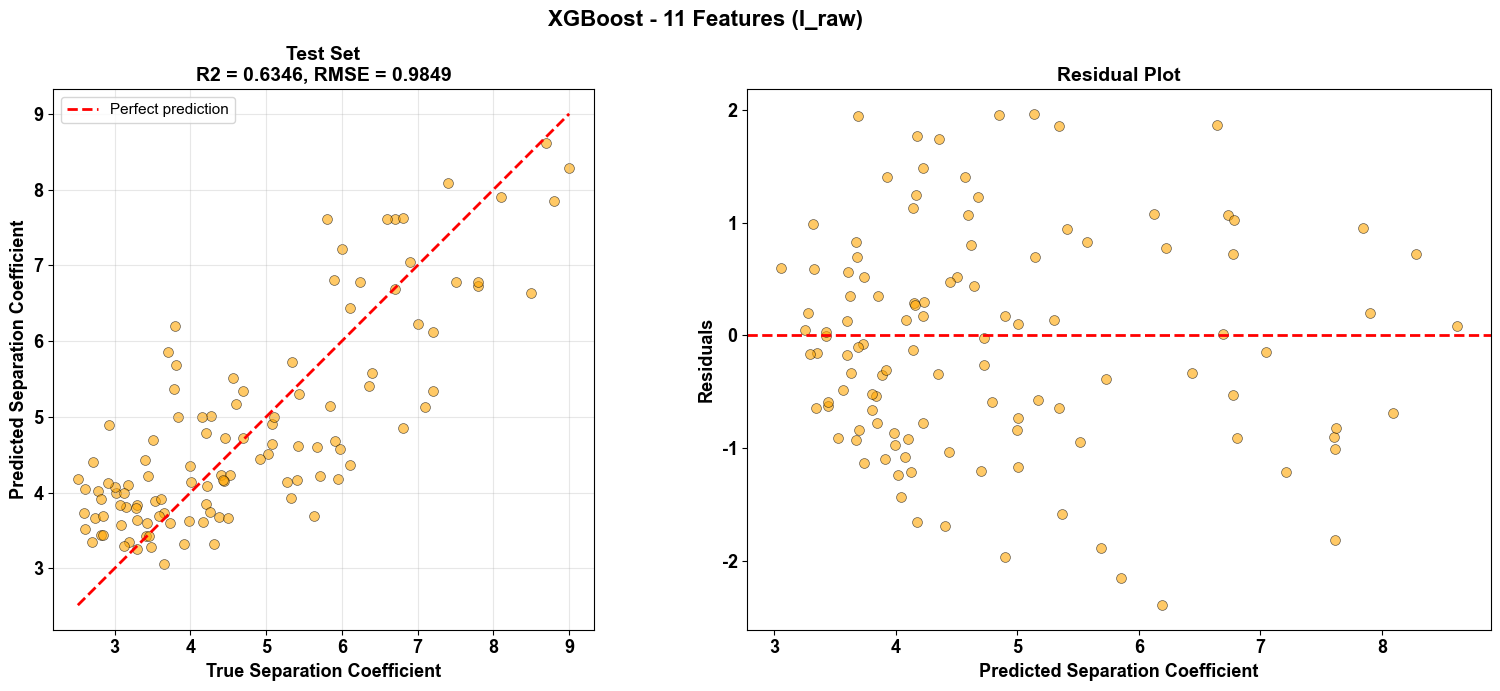

In [6]:
def plot_prediction(best_model):
    print("\n" + "=" * 100)
    print("STEP 3: PREDICTION PLOT")
    print("=" * 100)

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    ax = axes[0]
    ax.scatter(best_model["y_test"], best_model["y_test_pred"], alpha=0.6, s=50, color="orange", edgecolors="k", linewidth=0.5)
    min_val = min(best_model["y_test"].min(), best_model["y_test_pred"].min())
    max_val = max(best_model["y_test"].max(), best_model["y_test_pred"].max())
    ax.plot([min_val, max_val], [min_val, max_val], "r--", linewidth=2, label="Perfect prediction")
    ax.set_xlabel("True Separation Coefficient", fontsize=13, fontname="Arial", fontweight="bold")
    ax.set_ylabel("Predicted Separation Coefficient", fontsize=13, fontname="Arial", fontweight="bold")
    ax.set_title(f"Test Set\nR2 = {best_model['test_r2']:.4f}, RMSE = {best_model['test_rmse']:.4f}", fontsize=14, fontname="Arial", fontweight="bold")
    ax.tick_params(axis="both", which="both", labelsize=13)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontname("Arial")
        label.set_fontweight("bold")
    ax.legend(fontsize=11)
    ax.grid(alpha=0.3)
    ax.set_aspect("equal", adjustable="box")

    ax = axes[1]
    residuals = best_model["y_test"] - best_model["y_test_pred"]
    ax.scatter(best_model["y_test_pred"], residuals, alpha=0.6, s=50, color="orange", edgecolors="k", linewidth=0.5)
    ax.axhline(y=0, color="r", linestyle="--", linewidth=2)
    ax.set_xlabel("Predicted Separation Coefficient", fontsize=13, fontname="Arial", fontweight="bold")
    ax.set_ylabel("Residuals", fontsize=13, fontname="Arial", fontweight="bold")
    ax.set_title("Residual Plot", fontsize=14, fontname="Arial", fontweight="bold")
    ax.tick_params(axis="both", which="both", labelsize=13)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontname("Arial")
        label.set_fontweight("bold")

    fig.suptitle(f"{best_model['model_name']} - 11 Features (I_raw)", fontsize=16, fontweight="bold", y=0.98)
    plt.tight_layout()
    pred_file = OUTPUT_DIR / "final_prediction_I_raw.png"
    plt.savefig(pred_file, dpi=300, bbox_inches="tight")
    print(f"[OK] Prediction plot saved to: {pred_file}")
    plt.show()
    plt.close()


plot_prediction(best_model)


## SHAP and Feature Importance

This section saves SHAP summaries for both the held-out test set and the full 561-sample no-BO dataset. It also saves the native tree-model feature importance for the best model.



STEP 4: SHAP ANALYSIS


SHAP dataset: held-out test set (n=113)


[OK] SHAP swarm plot saved: outputs\final_model_11features_561_seed42_rs_from_eis\final_shap_I_raw\shap_swarm_test_set.png


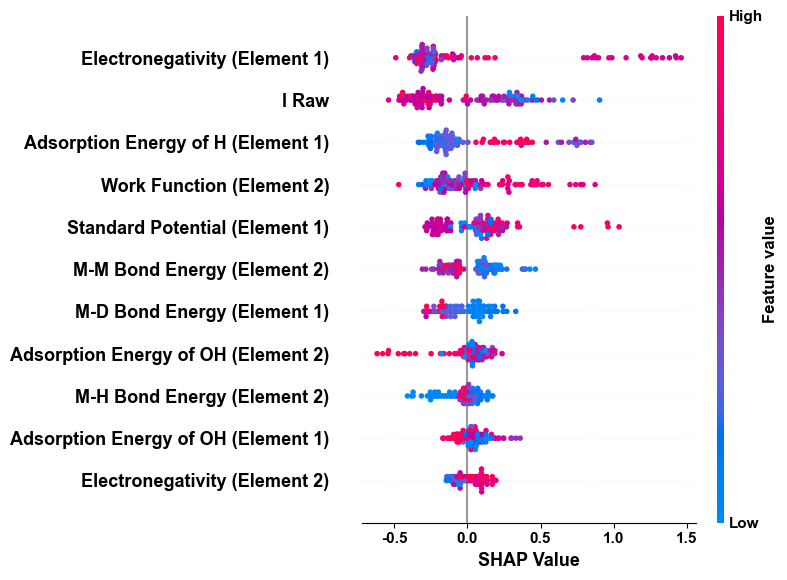

[OK] SHAP bar plot saved: outputs\final_model_11features_561_seed42_rs_from_eis\final_shap_I_raw\shap_bar_test_set.png


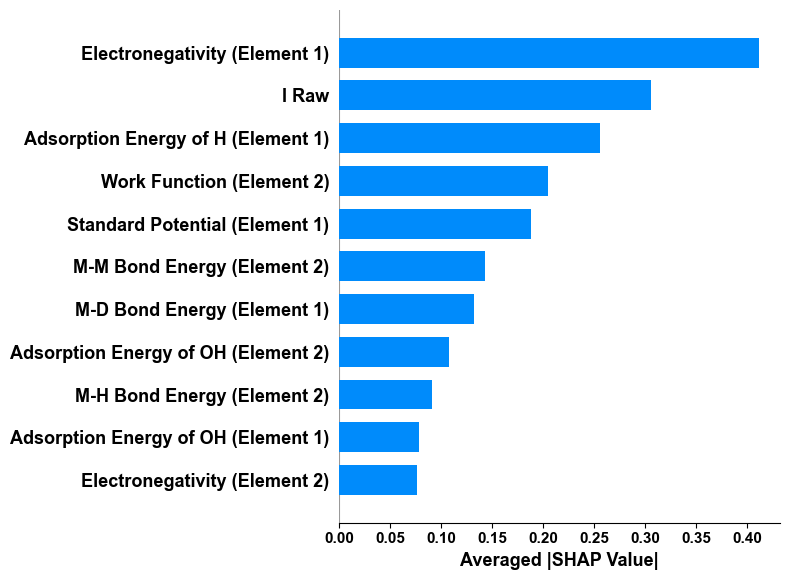

SHAP dataset: all no-BO samples (n=561)


[OK] SHAP swarm plot saved: outputs\final_model_11features_561_seed42_rs_from_eis\final_shap_I_raw\shap_swarm_all_samples.png


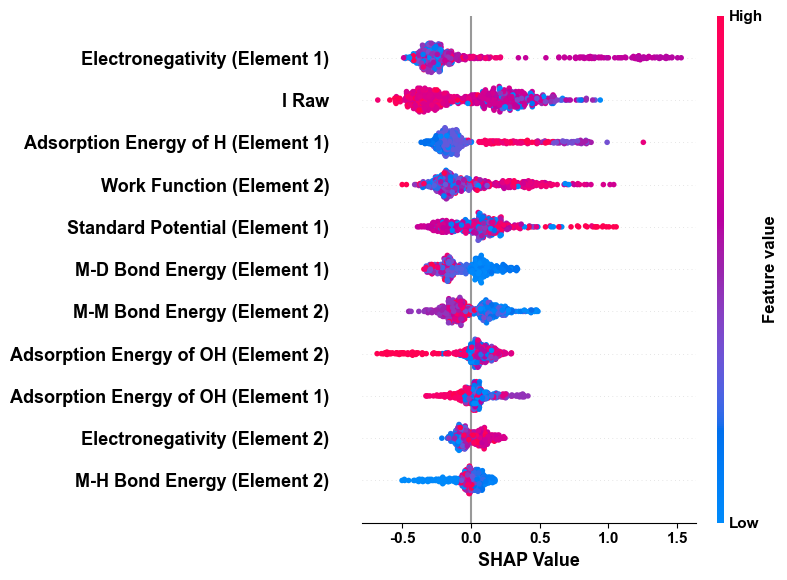

[OK] SHAP bar plot saved: outputs\final_model_11features_561_seed42_rs_from_eis\final_shap_I_raw\shap_bar_all_samples.png


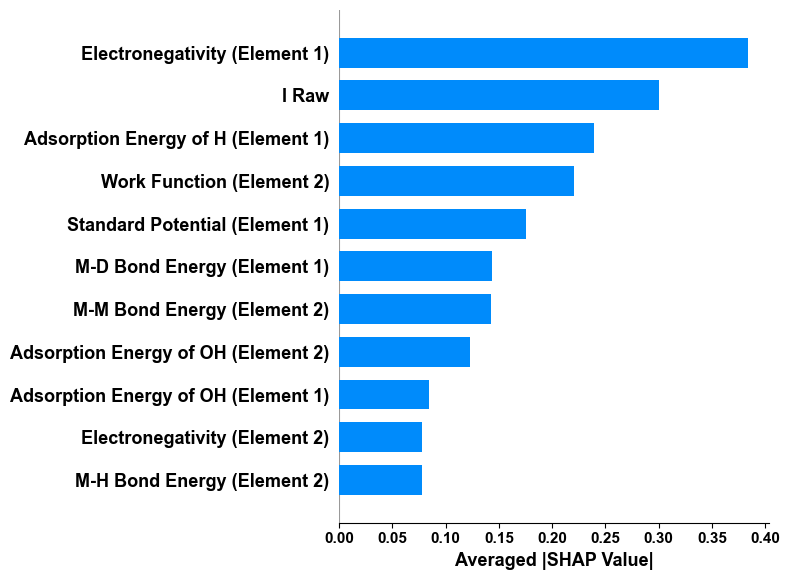

In [7]:
def map_feature_names(feature_name):
    feature_name = feature_name.replace("_", " ").title()
    feature_name = feature_name.replace("Element1", "(Element 1)").replace("Element2", "(Element 2)")
    feature_name = feature_name.replace("Fe Ads Avg", "Adsorption Energy of H")
    feature_name = feature_name.replace("Delta Eoh", "Adsorption Energy of OH")
    feature_name = feature_name.replace("Mm Bond", "M-M Bond Energy")
    feature_name = feature_name.replace("E Std", "Standard Potential")
    feature_name = feature_name.replace("Mh Bond Kj", "M-H Bond Energy")
    feature_name = feature_name.replace("Md Bond Kj", "M-D Bond Energy")
    feature_name = feature_name.replace("Frequency", "Frequency of")
    feature_name = feature_name.replace("Oh", "OH")
    feature_name = feature_name.replace("Zpe H", "ZPE for H")
    return feature_name


def perform_shap_analysis(best_model, X_all_selected):
    print("\n" + "=" * 100)
    print("STEP 4: SHAP ANALYSIS")
    print("=" * 100)

    shap_dir = OUTPUT_DIR / "final_shap_I_raw"
    if shap_dir.exists():
        shutil.rmtree(shap_dir)
    shap_dir.mkdir(parents=True, exist_ok=True)

    model = best_model["model"]
    explainer = shap.TreeExplainer(model)
    mapped_features = [map_feature_names(feature) for feature in SELECTED_FEATURES]

    def save_shap_pair(X_values, label, suffix, save_legacy_alias=False):
        X_values = X_values.copy().apply(pd.to_numeric, errors="coerce")
        shap_values = explainer.shap_values(X_values)
        n_samples = X_values.shape[0]
        print(f"SHAP dataset: {label} (n={n_samples})")

        plt.figure(figsize=(14, 10))
        shap.summary_plot(shap_values, X_values, feature_names=mapped_features, show=False)
        fig = plt.gcf()
        ax = fig.axes[0]
        ax.set_xlabel("SHAP Value", color="black", fontweight="bold")
        for ax in fig.axes:
            ax.tick_params(axis="both", colors="black", labelcolor="black")

            ax.xaxis.label.set_color("black")
            ax.yaxis.label.set_color("black")
            ax.title.set_color("black")

            ax.xaxis.label.set_fontweight("bold")
            ax.yaxis.label.set_fontweight("bold")
            ax.title.set_fontweight("bold")

            for label in ax.get_xticklabels() + ax.get_yticklabels():
                label.set_color("black")
                label.set_fontweight("bold")

            for text in ax.texts:
                text.set_color("black")
                text.set_fontweight("bold")
        
        plt.tight_layout()
        swarm_file = shap_dir / f"shap_swarm_{suffix}.png"
        plt.savefig(swarm_file, dpi=300, bbox_inches="tight")

        if save_legacy_alias:
            shutil.copyfile(swarm_file, shap_dir / "shap_swarm.png")
        print(f"[OK] SHAP swarm plot saved: {swarm_file}")
        plt.show()
        plt.close()

        plt.figure(figsize=(14, 10))
        shap.summary_plot(shap_values, X_values, feature_names=mapped_features, plot_type="bar", show=False)
        fig = plt.gcf()
        ax = fig.axes[0]
        ax.set_xlabel("Averaged |SHAP Value|", color="black", fontweight="bold")
        for ax in fig.axes:
            ax.tick_params(axis="both", colors="black", labelcolor="black")

            ax.xaxis.label.set_color("black")
            ax.yaxis.label.set_color("black")
            ax.title.set_color("black")

            ax.xaxis.label.set_fontweight("bold")
            ax.yaxis.label.set_fontweight("bold")
            ax.title.set_fontweight("bold")

            for label in ax.get_xticklabels() + ax.get_yticklabels():
                label.set_color("black")
                label.set_fontweight("bold")

            for text in ax.texts:
                text.set_color("black")
                text.set_fontweight("bold")

        plt.tight_layout()
        bar_file = shap_dir / f"shap_bar_{suffix}.png"
        plt.savefig(bar_file, dpi=300, bbox_inches="tight")
        if save_legacy_alias:
            shutil.copyfile(bar_file, shap_dir / "shap_bar.png")
        print(f"[OK] SHAP bar plot saved: {bar_file}")
        plt.show()
        plt.close()

    save_shap_pair(best_model["X_test"], "held-out test set", "test_set", save_legacy_alias=True)
    save_shap_pair(X_all_selected, "all no-BO samples", "all_samples")


perform_shap_analysis(best_model, X[SELECTED_FEATURES])

In [8]:
print("\n" + "=" * 100)
print("FINAL SUMMARY")
print("=" * 100)
print(f"Best model: {best_model['model_name']}")
print(f"Number of features: {len(SELECTED_FEATURES)}")
print(f"Test R2: {best_model['test_r2']:.4f}")
print(f"Test RMSE: {best_model['test_rmse']:.4f}")
print("Selected features:")
for i, feat in enumerate(SELECTED_FEATURES, 1):
    print(f"  {i}. {feat}")
print(f"Outputs saved to: {OUTPUT_DIR}")



FINAL SUMMARY
Best model: XGBoost
Number of features: 11
Test R2: 0.6346
Test RMSE: 0.9849
Selected features:
  1. I_raw
  2. work_function_element2
  3. MM_bond_element2
  4. E_std_element1
  5. FE_ads_avg_element1
  6. delta_EOH_element1
  7. delta_EOH_element2
  8. electronegativity_element1
  9. electronegativity_element2
  10. MH_bond_kJ_element2
  11. MD_bond_kJ_element1
Outputs saved to: outputs\final_model_11features_561_seed42_rs_from_eis


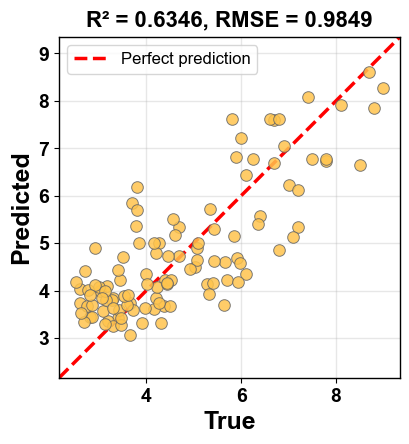

Saved to: outputs\final_model_11features_561_seed42_rs_from_eis\test_prediction_publication_style.png
Plot outputs:
  outputs\final_model_11features_561_seed42_rs_from_eis\final_prediction_I_raw.png
  outputs\final_model_11features_561_seed42_rs_from_eis\final_shap_I_raw\shap_bar.png
  outputs\final_model_11features_561_seed42_rs_from_eis\final_shap_I_raw\shap_bar_all_samples.png
  outputs\final_model_11features_561_seed42_rs_from_eis\final_shap_I_raw\shap_bar_test_set.png
  outputs\final_model_11features_561_seed42_rs_from_eis\final_shap_I_raw\shap_swarm.png
  outputs\final_model_11features_561_seed42_rs_from_eis\final_shap_I_raw\shap_swarm_all_samples.png
  outputs\final_model_11features_561_seed42_rs_from_eis\final_shap_I_raw\shap_swarm_test_set.png
  outputs\final_model_11features_561_seed42_rs_from_eis\test_prediction_publication_style.png
Plot manifest saved to: outputs\final_model_11features_561_seed42_rs_from_eis\plot_outputs_manifest.csv


In [9]:
# Publication-style test prediction plot

from sklearn.metrics import r2_score, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

y_true = np.asarray(best_model["y_test"])
y_pred = np.asarray(best_model["y_test_pred"])

r2 = r2_score(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))

fig, ax = plt.subplots(figsize=(4.2, 5.0))

ax.scatter(
    y_true,
    y_pred,
    s=70,
    color="#ffc44d",
    edgecolors="#666666",
    linewidths=0.7,
    alpha=0.85,
    zorder=3,
)

min_val = min(y_true.min(), y_pred.min())
max_val = max(y_true.max(), y_pred.max())
pad = 0.35
plot_min = min_val - pad
plot_max = max_val + pad

ax.plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    color="red",
    linestyle="--",
    linewidth=2.5,
    label="Perfect prediction",
    zorder=2,
)

ax.set_xlim(plot_min, plot_max)
ax.set_ylim(plot_min, plot_max)
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel("True", fontsize=18, fontweight="bold", color="black")
ax.set_ylabel("Predicted", fontsize=18, fontweight="bold", color="black")
ax.set_title(
    f"R² = {r2:.4f}, RMSE = {rmse:.4f}",
    fontsize=16,
    fontweight="bold",
    color="black",
    pad=8,
)

ax.grid(True, alpha=0.3, linewidth=1.0)

ax.tick_params(axis="both", labelsize=14, colors="black")
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontweight("bold")
    label.set_color("black")

legend = ax.legend(
    loc="upper left",
    frameon=True,
    fontsize=12,
)
for text in legend.get_texts():
    text.set_color("black")

for spine in ax.spines.values():
    spine.set_linewidth(1.0)
    spine.set_color("black")

plt.tight_layout()

out_file = OUTPUT_DIR / "test_prediction_publication_style.png"
plt.savefig(out_file, dpi=600, bbox_inches="tight")
plt.show()

print(f"Saved to: {out_file}")

plot_outputs = sorted(OUTPUT_DIR.rglob("*.png"))
manifest_file = OUTPUT_DIR / "plot_outputs_manifest.csv"
pd.DataFrame({
    "plot_file": [str(path.relative_to(OUTPUT_DIR)) for path in plot_outputs],
    "full_path": [str(path.resolve()) for path in plot_outputs],
}).to_csv(manifest_file, index=False)

print("Plot outputs:")
for path in plot_outputs:
    print(f"  {path}")
print(f"Plot manifest saved to: {manifest_file}")

